**Looped transformer series (pure PyTorch):**
[01 Universal Transformer](01_universal_transformer.ipynb) ·
[02 Adaptive Computation Time](02_act_halting.ipynb) ·
**03 Recurrent depth** ·
[04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) ·
[05 Mixture-of-Recursions](05_mixture_of_recursions.ipynb) ·
[06 Relaxed recursion](06_relaxed_recursion.ipynb) ·
[07 Scratchpad memory](07_scratchpad_memory.ipynb) ·
[08 Layer-sharing schedules](08_layer_sharing.ipynb)

# Looped transformers 03 - Recurrent depth: train once, think longer at test time

**Summary.** A *recurrent-depth* transformer splits the network into three parts. An unshared **prelude** reads the input. One **shared core block** is then looped `T` times over a latent state, and each pass re-injects the prelude output. Finally an unshared **coda** writes the prediction. You train it once with a *random* number of loops, and at test time you can choose how many loops to run. In this notebook we build that model from scratch in about 100 lines of PyTorch (175k parameters) and train six variants on 143k characters of Python docstrings. Then we measure five things: what each input-injection rule does to the hidden state, how much memory truncated backprop saves, whether running more loops at test time helps, whether a step embedding hurts outside the trained range, and why sandwich normalisation keeps long loops stable. **Main measured result:** with a sandwich-normalised core the model is completely stable out to 32 loops (3.284 bits/char at T = 4, 8, 24 and 32). But at this tiny scale extra loops beyond the trained range buy *nothing*: the state converges to a fixed point after about 6 passes.

### What you will learn

| # | Topic | What you will be able to do |
|---|-------|-----------------------------|
| 1 | Prelude / core / coda | Build a model whose middle block is reused `T` times, with unshared first and last layers |
| 2 | Input injection | Implement `none`, `add` and `concat` adapters and see what each does to the hidden-state norm |
| 3 | Random loop count | Train with `T ~ Uniform{2..8}` so one set of weights works for many depths |
| 4 | Truncated backprop | Keep gradients only for the last `k` passes and measure the memory / time saved |
| 5 | Test-time scaling | Evaluate held-out bits/char at `T = 1 ... 24` and see what really extrapolates |
| 6 | Sandwich norm | Stabilise the state over 32+ passes with a norm after every residual add |

**Prerequisites:** Python, basic PyTorch (tensors, `nn.Module`, autograd, an optimizer loop), the idea of attention.
Notebooks 01 (Universal Transformer) and 02 (ACT) help but are not required.

**Estimated runtime:** about 8-10 minutes on a laptop CPU with 2 threads (the measured total is printed in the last code cell).

### Setup

Only the standard library, `torch`, `numpy` and `matplotlib`. We pin the CPU to 2 threads (other jobs share the machine) and fix every seed so the numbers in the text match the outputs.

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(2)
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
NOTEBOOK_START = time.time()
print(f"torch {torch.__version__} | numpy {np.__version__} | threads {torch.get_num_threads()}")

torch 2.13.0 | numpy 2.5.1 | threads 2


## 1. Intuition

Think of a person solving a puzzle. They **read** the puzzle once (prelude), then **think** about it - turning the same mental procedure over and over (the core loop) - and finally **write down** the answer once (coda). Easy puzzles need a few rounds of thinking, hard ones need many. Crucially the *procedure* is the same each round; only the amount of thinking changes. While thinking they keep **glancing back at the puzzle text** so they do not drift off - that is *input injection*.

A **recurrent-depth transformer** (Geiping et al. 2025, "Huginn") does exactly this:

* **Prelude** `P`: a few ordinary transformer layers that turn tokens into an embedding `e`. Run once.
* **Core** `R`: one block (or a small stack) whose **weights are shared** and which is applied `T` times to a latent state `h`. Every pass re-reads `e` through an **adapter**.
* **Coda** `C`: a few ordinary layers plus the output head, run once on the final state.

Why keep the first and last layers *unshared*? The first layers do a very specific job - turning one-hot characters into a contextual representation - and the last layers must map whatever the loop produced into vocabulary logits. Those are **change-of-space** operations that you only need once; if the shared block had to do them too, it would have to behave differently on pass 1, on the middle passes and on the final pass, which is exactly what weight sharing forbids. Keeping them separate lets the core specialise in "refine the state", an operation that makes sense to repeat.

The payoff: **the same trained weights can be run with more loops at test time** to spend more compute. Whether that actually *helps* is something we will measure, not assume.

```mermaid
flowchart LR
    X["tokens x<br/>(B, L)"] --> EMB["token + position<br/>embedding"]
    EMB --> P["Prelude P<br/>(unshared block)"]
    P --> E["e (B, L, d)"]
    H0["h0 = 0<br/>(or e for 'none')"] --> A
    E --> A["adapter<br/>A(h, e)"]
    A --> R["Core R<br/>(shared block)"]
    R -->|"h_t, repeat T times"| A
    R --> C["Coda C<br/>(unshared block)"]
    C --> HEAD["LayerNorm + Linear"]
    HEAD --> Y["logits (B, L, V)"]
    E -. "re-injected every pass" .-> A
```

## 2. The math

Let $x \in \{0..V-1\}^{B \times L}$ be a batch of $B$ sequences of $L$ characters, $V$ the vocabulary size and $d$ the model width.

**Embedding and prelude** (run once):
$$e = P\big(W_{\text{tok}}[x] + W_{\text{pos}}[0..L-1]\big) \in \mathbb{R}^{B \times L \times d}$$

**Recurrence** (run $T$ times, $t = 1..T$, with shared weights in $R$ and $A$):
$$h_t = R\big(A(h_{t-1}, e) + s_t\big), \qquad h_0 = 0 \;\;(\text{or } h_0 = e \text{ for "none"})$$
where $s_t \in \mathbb{R}^d$ is an optional sinusoidal **step embedding** that tells the core which pass it is on ($s_t = 0$ if disabled).

**Three adapters** $A : \mathbb{R}^{B\times L\times d} \times \mathbb{R}^{B\times L\times d} \to \mathbb{R}^{B\times L\times d}$:
$$A_{\text{none}}(h, e) = h, \qquad A_{\text{add}}(h, e) = h + e, \qquad A_{\text{concat}}(h, e) = W_A [h ; e] + b_A,\; W_A \in \mathbb{R}^{d \times 2d}$$
We initialise $W_A = [I_d \;\; I_d]$, $b_A = 0$ so that `concat` starts out **identical** to `add` and then learns how much of each to keep.

**Two core blocks.** With $\text{Att}$ = causal multi-head self-attention, $\text{MLP}$ = Linear-GELU-Linear and $n_i$ = LayerNorms:
$$\text{pre-norm:}\quad u = z + \text{Att}(n_1(z)),\qquad R(z) = u + \text{MLP}(n_2(u))$$
$$\text{sandwich:}\quad u = n_2\big(z + \text{Att}(n_1(z))\big),\qquad R(z) = n_4\big(u + \text{MLP}(n_3(u))\big)$$

**Why `add` + pre-norm grows linearly.** In the pre-norm block the input passes through untouched on the residual path: $R(z) = z + \Delta(z)$. With `add`, $z = h_{t-1} + e$, so
$$h_t = h_{t-1} + e + \Delta_t \;\;\Rightarrow\;\; h_T = T\,e + \sum_{t=1}^{T} \Delta_t .$$
The term $T e$ means $\lVert h_T\rVert$ grows roughly **linearly in $T$** unless the updates $\Delta_t$ learn to cancel $e$ exactly. The sandwich block ends with a LayerNorm, so $\lVert h_t \rVert \approx \sqrt{d}$ (times the norm's gain) no matter how many passes ran.

**Output and loss** (run once): $\;\text{logits} = W_{\text{out}}\, n_f\big(C(h_T)\big) \in \mathbb{R}^{B\times L\times V}$, and
$$\mathcal{L} = -\frac{1}{BL}\sum_{b,i} \log p(x_{b,i+1} \mid x_{b,\le i}), \qquad \text{bits/char} = \mathcal{L} / \ln 2 .$$

**Truncated backprop.** With $T$ passes and truncation $k$, passes $1..T-k$ run under `torch.no_grad()`: $h_{T-k}$ is treated as a constant. Gradients still reach the prelude because $e$ enters each of the last $k$ passes through the adapter. Activation memory drops from $O(T)$ to $O(k)$ blocks.

**Training-time loop sampling.** Each step draws $T \sim \text{Uniform}\{2,\dots,8\}$ (Huginn draws from a heavy-tailed log-normal Poisson with mean 32 and uses $k=8$; we scale that down).

## 3. Data and tokenizer

We need data before we can test the blocks, so it comes first.

* **Toy corpus** - four 48-character sentences with two genuine choice points (`model`/`robot`, `write`/`spell`). Small enough to look inside.
* **Docstring corpus** - real English from the Python standard library. Split 90/10 **by position** (the last 10% is validation, never seen in training). We train on random 64-character windows and report validation **bits per character**.

In [2]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell

def docstring_corpus() -> str:
    """Real English text that ships with Python: docstrings of standard-library modules."""
    import importlib, inspect, re
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))

DOC_TEXT = docstring_corpus()
print(f"docstring corpus: {len(DOC_TEXT):,} characters, {len(set(DOC_TEXT))} distinct")
print("sample:", DOC_TEXT[:160])

docstring corpus: 142,997 characters, 98 distinct
sample: A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is pu


In [3]:
class CharTokenizer:
    """Maps each distinct character to an integer id and back."""

    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {ch: i for i, ch in enumerate(self.chars)}
        self.itos = {i: ch for i, ch in enumerate(self.chars)}

    @property
    def vocab_size(self) -> int:
        return len(self.chars)

    def encode(self, s: str) -> list[int]:
        return [self.stoi[ch] for ch in s]

    def decode(self, ids: list[int]) -> str:
        return "".join(self.itos[i] for i in ids)


# One vocabulary covering both corpora (the toy characters are all inside the docstrings anyway).
tok = CharTokenizer(DOC_TEXT + "".join(TOY_CORPUS))
VOCAB = tok.vocab_size
assert tok.decode(tok.encode(TOY_CORPUS[0])) == TOY_CORPUS[0]

doc_ids = torch.tensor(tok.encode(DOC_TEXT), dtype=torch.long)
n_train = int(0.9 * len(doc_ids))
train_ids, val_ids = doc_ids[:n_train], doc_ids[n_train:]
CONTEXT = 64  # characters the model sees per window

def get_batch(ids: torch.Tensor, batch_size: int, length: int, gen: torch.Generator) -> tuple[torch.Tensor, torch.Tensor]:
    """Random windows: x = chars [s, s+length), y = chars [s+1, s+length+1) (next-char targets)."""
    starts = torch.randint(0, len(ids) - length - 1, (batch_size,), generator=gen)
    x = torch.stack([ids[s:s + length] for s in starts.tolist()])
    y = torch.stack([ids[s + 1:s + length + 1] for s in starts.tolist()])
    return x, y

# A FIXED held-out set: the first N non-overlapping 65-char windows of the validation split.
N_VAL_WINDOWS = 192
val_starts = list(range(0, len(val_ids) - CONTEXT - 1, CONTEXT + 1))[:N_VAL_WINDOWS]
VAL_X = torch.stack([val_ids[s:s + CONTEXT] for s in val_starts])
VAL_Y = torch.stack([val_ids[s + 1:s + CONTEXT + 1] for s in val_starts])

toy_ids = torch.tensor([tok.encode(s) for s in TOY_CORPUS])  # (4, 48)
TOY_X, TOY_Y = toy_ids[:, :-1], toy_ids[:, 1:]                 # (4, 47) each

print(f"vocab size V = {VOCAB}")
print(f"train chars = {len(train_ids):,} | val chars = {len(val_ids):,} | held-out eval = {VAL_X.numel():,} chars "
      f"({N_VAL_WINDOWS} windows x {CONTEXT})")
print("toy batch:", tuple(TOY_X.shape), "| x[0] =", repr(tok.decode(TOY_X[0].tolist())))
assert torch.equal(VAL_X[0, 1:], VAL_Y[0, :-1])  # targets are inputs shifted by one

vocab size V = 98
train chars = 128,697 | val chars = 14,300 | held-out eval = 12,288 chars (192 windows x 64)
toy batch: (4, 47) | x[0] = 'the tiny model learned to write this sentence :'


## 4. Building blocks from scratch

### 4.1 Causal mask
`nn.MultiheadAttention` takes a boolean `attn_mask` where **`True` means "may NOT attend"**. For next-character prediction position `i` must only see positions `<= i`, so we block everything strictly above the diagonal. Without this the model could read the answer and the loss would collapse to ~0 while learning nothing.

In [4]:
def causal_mask(length: int) -> torch.Tensor:
    """(L, L) bool mask, True above the diagonal = future positions that must be hidden."""
    return torch.triu(torch.ones(length, length, dtype=torch.bool), diagonal=1)

print(causal_mask(5).int())
assert causal_mask(5)[2, 3] and not causal_mask(5)[3, 2]

tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)


### 4.2 The transformer block: pre-norm and sandwich variants
One class, one flag. `sandwich=False` is the series' reference pre-norm block. `sandwich=True` adds a LayerNorm **after** each residual add (the Huginn recipe), so the block's output always has a controlled scale - important when the block is about to be applied to its own output dozens of times.

In [5]:
class MLP(nn.Module):
    """Position-wise feed-forward network: Linear -> GELU -> Linear."""

    def __init__(self, d_model: int, expansion: int = 4) -> None:
        super().__init__()
        self.fc_in = nn.Linear(d_model, expansion * d_model)
        self.fc_out = nn.Linear(expansion * d_model, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc_out(F.gelu(self.fc_in(x)))


class Block(nn.Module):
    """Causal transformer block. sandwich=False: pre-norm. sandwich=True: norm before AND after each sublayer."""

    def __init__(self, d_model: int, n_heads: int, sandwich: bool = False) -> None:
        super().__init__()
        self.sandwich = sandwich
        self.norm_attn_in = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        self.norm_mlp_in = nn.LayerNorm(d_model)
        self.mlp = MLP(d_model)
        if sandwich:
            self.norm_attn_out = nn.LayerNorm(d_model)  # applied to (residual + attention)
            self.norm_mlp_out = nn.LayerNorm(d_model)   # applied to (residual + MLP)

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        a = self.norm_attn_in(x)
        attn_out, _ = self.attn(a, a, a, attn_mask=mask, need_weights=False)
        x = x + attn_out
        if self.sandwich:
            x = self.norm_attn_out(x)
        x = x + self.mlp(self.norm_mlp_in(x))
        if self.sandwich:
            x = self.norm_mlp_out(x)
        return x

In [6]:
torch.manual_seed(SEED)
d_demo, L_demo = 64, 10
x_demo = torch.randn(2, L_demo, d_demo)
for sandwich in (False, True):
    blk = Block(d_demo, 4, sandwich=sandwich)
    out = blk(x_demo, causal_mask(L_demo))
    assert out.shape == x_demo.shape
    # Causality: changing position 6 must not change outputs at positions 0..5.
    x_changed = x_demo.clone()
    x_changed[:, 6] += 10.0
    out_changed = blk(x_changed, causal_mask(L_demo))
    assert torch.allclose(out[:, :6], out_changed[:, :6], atol=1e-5), "future leak!"
    assert not torch.allclose(out[:, 6:], out_changed[:, 6:])
    print(f"sandwich={sandwich!s:5}: out {tuple(out.shape)}, mean token norm {out.norm(dim=-1).mean():.2f} "
          f"(sqrt(d) = {math.sqrt(d_demo):.2f}) | causal check passed")

sandwich=False: out (2, 10, 64), mean token norm 8.59 (sqrt(d) = 8.00) | causal check passed
sandwich=True : out (2, 10, 64), mean token norm 8.00 (sqrt(d) = 8.00) | causal check passed


Note the sandwich output norm is exactly $\sqrt{d} = 8$: the final LayerNorm (gain 1 at init) rescales every token vector to unit variance per dimension.

### 4.3 Input injection adapters

In [7]:
class InputInjection(nn.Module):
    """Combines the previous latent state h with the prelude output e. mode in {'none', 'add', 'concat'}."""

    def __init__(self, d_model: int, mode: str) -> None:
        super().__init__()
        assert mode in ("none", "add", "concat")
        self.mode = mode
        if mode == "concat":
            self.proj = nn.Linear(2 * d_model, d_model)
            with torch.no_grad():  # initialise to h + e: weight = [I | I], bias = 0
                eye = torch.eye(d_model)
                self.proj.weight.copy_(torch.cat([eye, eye], dim=1))
                self.proj.bias.zero_()

    def initial_state(self, e: torch.Tensor) -> torch.Tensor:
        """h_0. 'none' has no other way to see the input, so it starts FROM e; the others start from zero."""
        return e if self.mode == "none" else torch.zeros_like(e)

    def forward(self, h: torch.Tensor, e: torch.Tensor) -> torch.Tensor:
        if self.mode == "none":
            return h
        if self.mode == "add":
            return h + e
        return self.proj(torch.cat([h, e], dim=-1))

In [8]:
h_demo, e_demo = torch.randn(2, L_demo, d_demo), torch.randn(2, L_demo, d_demo)
inj = {m: InputInjection(d_demo, m) for m in ("none", "add", "concat")}
assert torch.equal(inj["none"](h_demo, e_demo), h_demo)
# The same equation implemented two ways: the concat Linear at init == plain addition.
assert torch.allclose(inj["concat"](h_demo, e_demo), inj["add"](h_demo, e_demo), atol=1e-6)
# All three feed exactly e into the core on pass 1.
for m, a in inj.items():
    assert torch.allclose(a(a.initial_state(e_demo), e_demo), e_demo, atol=1e-6), m
print("concat adapter params:", sum(p.numel() for p in inj["concat"].parameters()), "| all adapter checks passed")

concat adapter params: 8256 | all adapter checks passed


### 4.4 Sinusoidal step embedding
The classic Transformer position encoding, but indexed by **loop step `t`** instead of token position. It gives the core a way to behave differently on different passes - which may or may not be a good idea when we later ask for passes it never saw in training.

In [9]:
def step_embedding(step: int, d_model: int) -> torch.Tensor:
    """(d,) vector: [sin(t w_0), cos(t w_0), sin(t w_1), cos(t w_1), ...], w_i = 10000^(-2i/d)."""
    half = d_model // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, dtype=torch.float32) * 2 / d_model)
    angles = step * freqs
    return torch.stack([torch.sin(angles), torch.cos(angles)], dim=-1).reshape(d_model)

emb_table = torch.stack([step_embedding(t, 64) for t in range(1, 33)])
print("table", tuple(emb_table.shape), "| norm of each row =", f"{emb_table[0].norm():.3f}", "(always sqrt(d/2))")
assert torch.allclose(emb_table.norm(dim=-1), torch.full((32,), math.sqrt(32)), atol=1e-4)
cos_sim = F.cosine_similarity(emb_table[:, None], emb_table[None], dim=-1)
print(f"cosine(t=4, t=5) = {cos_sim[3, 4]:.3f} | cosine(t=4, t=24) = {cos_sim[3, 23]:.3f}")

table (32, 64) | norm of each row = 5.657 (always sqrt(d/2))
cosine(t=4, t=5) = 0.966 | cosine(t=4, t=24) = 0.590


## 5. The full model

`forward(x, n_loops=T, n_grad=k)` runs the prelude once, the core `T` times, and the coda once. `n_grad=None` means full backprop through all passes; `n_grad=k` runs the first `T-k` passes under `torch.no_grad()`. `return_states=True` also returns every intermediate state `h_1..h_T`, which we use to look inside.

In [10]:
class RecurrentDepthLM(nn.Module):
    """Prelude (unshared) -> core block looped T times with input injection -> coda (unshared) -> head."""

    def __init__(self, vocab_size: int, d_model: int = 64, n_heads: int = 4, max_len: int = 64,
                 n_prelude: int = 1, n_coda: int = 1, injection: str = "concat",
                 sandwich_core: bool = True, use_step_embedding: bool = False) -> None:
        super().__init__()
        self.d_model = d_model
        self.use_step_embedding = use_step_embedding
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.prelude = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_prelude)])
        self.adapter = InputInjection(d_model, injection)
        self.core = Block(d_model, n_heads, sandwich=sandwich_core)  # the ONLY looped weights
        self.coda = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_coda)])
        self.norm_final = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)

    def embed(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Tokens (B, L) -> prelude output e (B, L, d)."""
        positions = torch.arange(x.shape[1], device=x.device)
        e = self.tok_emb(x) + self.pos_emb(positions)
        for block in self.prelude:
            e = block(e, mask)
        return e

    def core_step(self, h: torch.Tensor, e: torch.Tensor, step: int, mask: torch.Tensor) -> torch.Tensor:
        """One pass of the loop: h_t = R(A(h_{t-1}, e) + s_t)."""
        z = self.adapter(h, e)
        if self.use_step_embedding:
            z = z + step_embedding(step, self.d_model)
        return self.core(z, mask)

    def decode(self, h: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Final state (B, L, d) -> logits (B, L, V)."""
        for block in self.coda:
            h = block(h, mask)
        return self.head(self.norm_final(h))

    def forward(self, x: torch.Tensor, n_loops: int, n_grad: int | None = None,
                return_states: bool = False):
        mask = causal_mask(x.shape[1])
        e = self.embed(x, mask)
        h = self.adapter.initial_state(e)
        states = []
        for t in range(1, n_loops + 1):
            keep_graph = n_grad is None or t > n_loops - n_grad  # only the last k passes
            with torch.set_grad_enabled(keep_graph and torch.is_grad_enabled()):
                h = self.core_step(h, e, t, mask)
            if return_states:
                states.append(h)
        logits = self.decode(h, mask)
        return (logits, states) if return_states else logits

In [11]:
torch.manual_seed(SEED)
model = RecurrentDepthLM(VOCAB)
xb = VAL_X[:3]
logits, states = model(xb, n_loops=5, return_states=True)
print("logits", tuple(logits.shape), "| states:", len(states), "x", tuple(states[0].shape))
assert logits.shape == (3, CONTEXT, VOCAB) and len(states) == 5

# (1) Same equation two ways: decoding the 3rd intermediate state == running with n_loops=3.
mask = causal_mask(CONTEXT)
assert torch.allclose(model.decode(states[2], mask), model(xb, n_loops=3), atol=1e-5)

# (2) Causality through the whole looped model: perturb token 40, logits 0..39 must not move.
x_changed = xb.clone()
x_changed[:, 40] = (x_changed[:, 40] + 1) % VOCAB
assert torch.allclose(model(xb, 8)[:, :40], model(x_changed, 8)[:, :40], atol=1e-5)

# (3) Truncated backprop: forward value identical, gradients flow everywhere, but differ from full BPTT.
def grads_for(n_grad: int | None) -> tuple[float, dict[str, torch.Tensor]]:
    model.zero_grad(set_to_none=True)
    loss = F.cross_entropy(model(xb, n_loops=6, n_grad=n_grad).reshape(-1, VOCAB), VAL_Y[:3].reshape(-1))
    loss.backward()
    return loss.item(), {n: p.grad.clone() for n, p in model.named_parameters()}

loss_full, g_full = grads_for(None)
loss_k6, g_k6 = grads_for(6)
loss_k2, g_k2 = grads_for(2)
assert loss_full == loss_k2 == loss_k6
assert all(torch.allclose(g_full[n], g_k6[n]) for n in g_full)          # k = T  is full backprop
assert all(g_k2[n].abs().sum() > 0 for n in g_k2), "some parameter got no gradient"
assert g_k2["prelude.0.mlp.fc_in.weight"].abs().sum() > 0                 # prelude still learns via e
diff = (g_full["core.mlp.fc_in.weight"] - g_k2["core.mlp.fc_in.weight"]).norm() / g_full["core.mlp.fc_in.weight"].norm()
print(f"loss identical ({loss_full:.4f}); relative core-grad difference full vs k=2: {diff:.3f}")
print("all model checks passed")

logits (3, 64, 98) | states: 5 x (3, 64, 64)


loss identical (4.8150); relative core-grad difference full vs k=2: 0.187
all model checks passed


### Parameters vs compute

The headline property of a looped model: **parameters are fixed, compute is a dial.** Below, "effective depth" is the number of block applications per token (prelude + `T` x core + coda); FLOPs per token scale with it. The last column is the parameter count an *unshared* stack of the same depth would need.

In [12]:
def n_params(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())

parts = {"embeddings": n_params(model.tok_emb) + n_params(model.pos_emb), "prelude": n_params(model.prelude),
         "adapter": n_params(model.adapter), "core (shared)": n_params(model.core),
         "coda + head": n_params(model.coda) + n_params(model.norm_final) + n_params(model.head)}
for name, count in parts.items():
    print(f"{name:15s} {count:8,d}")
total = n_params(model)
print(f"{'total':15s} {total:8,d}\n")

block_params = n_params(Block(64, 4))
print(f"{'T':>3} | {'eff. depth':>10} | {'params':>8} | {'rel. FLOPs/token':>16} | {'unshared same depth':>20}")
for T in (1, 2, 4, 8, 16, 24):
    depth = 1 + T + 1
    print(f"{T:>3} | {depth:>10} | {total:>8,d} | {depth / 6:>16.2f}x | {total - n_params(model.core) + T * block_params:>20,d}")

embeddings        10,368
prelude           49,984
adapter            8,256
core (shared)     50,240
coda + head       56,384
total            175,232

  T | eff. depth |   params | rel. FLOPs/token |  unshared same depth
  1 |          3 |  175,232 |             0.50x |              174,976
  2 |          4 |  175,232 |             0.67x |              224,960
  4 |          6 |  175,232 |             1.00x |              324,928
  8 |         10 |  175,232 |             1.67x |              524,864
 16 |         18 |  175,232 |             3.00x |              924,736
 24 |         26 |  175,232 |             4.33x |            1,324,608


## 6. Training loop

Written out in full: sample a batch, **sample a loop count**, forward with truncation, cross-entropy, backward, clip, AdamW step. A short linear warm-up followed by cosine decay. Every run below uses the same init seed and the same batch order, so differences come from the architecture or the loop schedule only.

In [13]:
def lr_at(step: int, total_steps: int, peak_lr: float, warmup: int = 50) -> float:
    if step < warmup:
        return peak_lr * (step + 1) / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    return peak_lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))


@torch.no_grad()
def eval_bpc(model: RecurrentDepthLM, n_loops: int, x: torch.Tensor = None, y: torch.Tensor = None,
             chunk: int = 96) -> float:
    """Held-out bits per character at a given loop count."""
    x = VAL_X if x is None else x
    y = VAL_Y if y is None else y
    model.eval()
    total_nll, total_tokens = 0.0, 0
    for i in range(0, len(x), chunk):
        logits = model(x[i:i + chunk], n_loops=n_loops)
        total_nll += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y[i:i + chunk].reshape(-1),
                                     reduction="sum").item()
        total_tokens += y[i:i + chunk].numel()
    model.train()
    return total_nll / total_tokens / math.log(2)


def train_lm(model: RecurrentDepthLM, n_steps: int, sample_loops, n_grad: int | None,
             peak_lr: float = 3e-3, batch_size: int = 32, seed: int = SEED,
             data: tuple[torch.Tensor, torch.Tensor] | None = None, eval_every: int = 0) -> dict:
    """data=None -> random docstring windows; otherwise a fixed (x, y) batch (the toy corpus)."""
    opt = torch.optim.AdamW(model.parameters(), lr=peak_lr, betas=(0.9, 0.95), weight_decay=0.01)
    gen = torch.Generator().manual_seed(seed)  # batch order
    rng = random.Random(seed)                  # loop-count order
    history = {"loss": [], "loops": [], "val_step": [], "val_bpc": []}
    start = time.time()
    for step in range(n_steps):
        for group in opt.param_groups:
            group["lr"] = lr_at(step, n_steps, peak_lr)
        x, y = get_batch(train_ids, batch_size, CONTEXT, gen) if data is None else data
        n_loops = sample_loops(rng)
        logits = model(x, n_loops=n_loops, n_grad=n_grad)
        loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        history["loss"].append(loss.item())
        history["loops"].append(n_loops)
        if eval_every and (step + 1) % eval_every == 0:
            history["val_step"].append(step + 1)
            history["val_bpc"].append(eval_bpc(model, 4))
    history["seconds"] = time.time() - start
    return history


def fixed_loops(T: int):
    return lambda rng: T

def random_loops(low: int = 2, high: int = 8):
    return lambda rng: rng.randint(low, high)  # inclusive on both ends

### 6.1 A first run on the toy corpus

Four sentences, random `T` in 2..8, truncation `k = 4`, 300 steps. The best possible loss is not zero: at the two choice points (`m`/`r` after "the tiny ", `w`/`s` after "learned to ") the right answer is a coin flip, worth 1 bit each. Over 47 predicted characters per sentence that is a floor of $2/47 \approx 0.043$ bits/char.

In [14]:
torch.manual_seed(SEED)
toy_model = RecurrentDepthLM(VOCAB, injection="concat", sandwich_core=True)
toy_hist = train_lm(toy_model, 300, random_loops(2, 8), n_grad=4, peak_lr=3e-3, data=(TOY_X, TOY_Y))
toy_bpc = {T: eval_bpc(toy_model, T, TOY_X, TOY_Y) for T in (1, 2, 4, 8, 16)}
print(f"trained in {toy_hist['seconds']:.1f}s | floor = {2 / 47:.3f} bits/char")
print("toy bits/char by T:", {T: round(v, 3) for T, v in toy_bpc.items()})

trained in 6.6s | floor = 0.043 bits/char
toy bits/char by T: {1: 0.043, 2: 0.043, 4: 0.043, 8: 0.043, 16: 0.043}


### 6.2 The main runs on the docstring corpus

Six models, all `d = 64`, 4 heads, 1 prelude block + 1 shared core block + 1 coda block, trained for the same number of steps on the same batches:

| run | injection | core block | loops during training | step emb. |
|-----|-----------|-----------|-----------------------|-----------|
| `none / pre-norm` | none | pre-norm | random 2..8, k=4 | no |
| `add / pre-norm` | add | pre-norm | random 2..8, k=4 | no |
| `concat / pre-norm` | concat | pre-norm | random 2..8, k=4 | no |
| `concat / sandwich` | concat | sandwich | random 2..8, k=4 | no |
| `fixed T=4` | concat | sandwich | always 4 (full backprop) | no |
| `random + step emb` | concat | sandwich | random 2..8, k=4 | yes |

This cell is the expensive one (about 1 minute per run).

In [15]:
N_STEPS = 800
RUNS = {
    "none / pre-norm":   dict(injection="none",   sandwich_core=False, loops=random_loops(), n_grad=4),
    "add / pre-norm":    dict(injection="add",    sandwich_core=False, loops=random_loops(), n_grad=4),
    "concat / pre-norm": dict(injection="concat", sandwich_core=False, loops=random_loops(), n_grad=4),
    "concat / sandwich": dict(injection="concat", sandwich_core=True,  loops=random_loops(), n_grad=4),
    "fixed T=4":         dict(injection="concat", sandwich_core=True,  loops=fixed_loops(4), n_grad=None),
    "random + step emb": dict(injection="concat", sandwich_core=True,  loops=random_loops(), n_grad=4,
                              step_emb=True),
}
models, histories = {}, {}
for name, cfg in RUNS.items():
    torch.manual_seed(SEED)  # identical init for every run (where shapes match)
    models[name] = RecurrentDepthLM(VOCAB, injection=cfg["injection"], sandwich_core=cfg["sandwich_core"],
                                    use_step_embedding=cfg.get("step_emb", False))
    histories[name] = train_lm(models[name], N_STEPS, cfg["loops"], cfg["n_grad"], eval_every=200)
    h = histories[name]
    print(f"{name:18s} params {n_params(models[name]):,} | {h['seconds']:5.1f}s | "
          f"final train loss {np.mean(h['loss'][-50:]):.3f} nats | val bpc @T=4: {h['val_bpc'][-1]:.3f}")

none / pre-norm    params 166,720 | 108.6s | final train loss 2.003 nats | val bpc @T=4: 3.443


add / pre-norm     params 166,720 | 160.1s | final train loss 1.989 nats | val bpc @T=4: 3.459


concat / pre-norm  params 174,976 | 147.7s | final train loss 2.110 nats | val bpc @T=4: 3.583


concat / sandwich  params 175,232 | 152.0s | final train loss 1.785 nats | val bpc @T=4: 3.284


fixed T=4          params 175,232 | 156.2s | final train loss 1.782 nats | val bpc @T=4: 3.281


random + step emb  params 175,232 | 105.5s | final train loss 1.797 nats | val bpc @T=4: 3.304


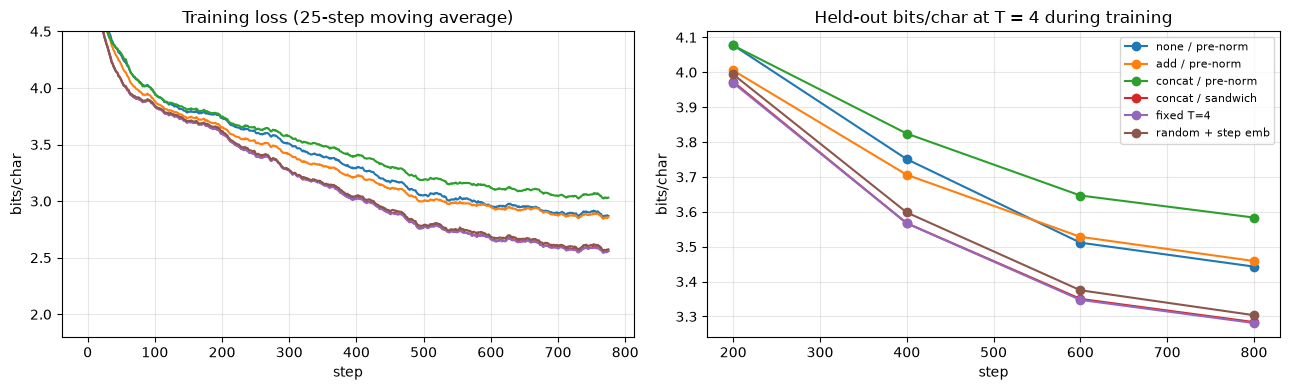

In [16]:
def smooth(values: list[float], window: int = 25) -> np.ndarray:
    return np.convolve(values, np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axes[0].plot(smooth(h["loss"]) / math.log(2), label=name)
    axes[1].plot(h["val_step"], h["val_bpc"], marker="o", label=name)
axes[0].set(title="Training loss (25-step moving average)", xlabel="step", ylabel="bits/char", ylim=(1.8, 4.5))
axes[1].set(title="Held-out bits/char at T = 4 during training", xlabel="step", ylabel="bits/char")
for ax in axes:
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Look inside

### 7.1 Toy corpus: what does the state "know" after each pass?
We decode every intermediate state `h_t` with the coda (the "logit lens") and plot the probability assigned to the **correct** next character, for each pass `t` (rows) and each position (columns). The two choice points should top out at ~0.5; everything else should approach 1.

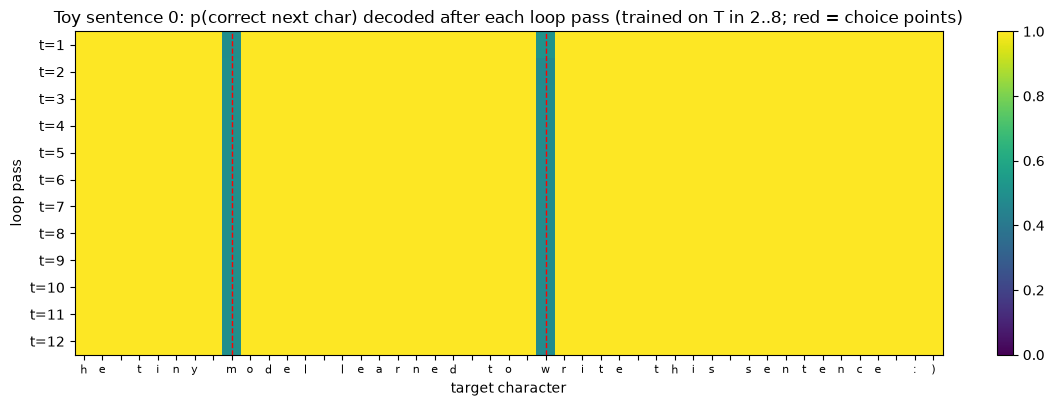

mean p(correct) per pass, all positions: [0.979, 0.979, 0.979, 0.979, 0.979, 0.979, 0.979, 0.979, 0.979, 0.979, 0.979, 0.979]
p at choice points (sentence 0), per pass: [[0.49, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5], [0.51, 0.48, 0.48, 0.48, 0.48, 0.48, 0.48, 0.48, 0.48, 0.48, 0.48, 0.48]]


In [17]:
@torch.no_grad()
def per_pass_correct_prob(model: RecurrentDepthLM, x: torch.Tensor, y: torch.Tensor, n_loops: int) -> torch.Tensor:
    """(n_loops, B, L) probability of the true next token when decoding h_1..h_T."""
    model.eval()
    _, states = model(x, n_loops=n_loops, return_states=True)
    mask = causal_mask(x.shape[1])
    probs = [model.decode(h, mask).softmax(-1).gather(-1, y[..., None])[..., 0] for h in states]
    model.train()
    return torch.stack(probs)

toy_probs = per_pass_correct_prob(toy_model, TOY_X, TOY_Y, n_loops=12)  # (12, 4, 47)
choice_positions = [TOY_CORPUS[0].index("model") - 1, TOY_CORPUS[0].index("write") - 1]

fig, ax = plt.subplots(figsize=(14, 4.2))
im = ax.imshow(toy_probs[:, 0].numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(47))
ax.set_xticklabels(list(TOY_CORPUS[0][1:]), fontsize=8)
ax.set_yticks(range(12))
ax.set_yticklabels([f"t={t}" for t in range(1, 13)])
for p in choice_positions:
    ax.axvline(p, color="red", lw=1, ls="--")
ax.set(title="Toy sentence 0: p(correct next char) decoded after each loop pass (trained on T in 2..8; red = choice points)",
       xlabel="target character", ylabel="loop pass")
plt.colorbar(im, ax=ax)
plt.show()
print("mean p(correct) per pass, all positions:", [round(v, 3) for v in toy_probs.mean(dim=(1, 2)).tolist()])
print("p at choice points (sentence 0), per pass:", [[round(v, 2) for v in toy_probs[:, 0, p].tolist()] for p in choice_positions])

**What we see.** The toy corpus is too easy to need depth. After 300 steps the model reaches the theoretical floor of 0.043 bits/char **already at T = 1**, and every pass decodes to the same thing. Mean p(correct) is 0.979 for passes 1 through 12. At the two choice points the probability is 0.49-0.51, the correct coin flip. So the heatmap looks the same in every row. That is a real finding, not a bug: **looping only helps when there is computation left to do.** Here one prelude block, one core pass and one coda block can already memorise four sentences. Notice also that the model was trained only on T = 2..8 and still decodes perfectly at T = 1 and T = 12. The latent state has settled and extra passes leave it unchanged (Section 7.3 measures this directly on real text).

### 7.2 State norm per pass: the effect of input injection
For the three pre-norm models, run 24 passes on held-out text and record the mean per-token norm $\lVert h_t \rVert_2$. We also show the same models **at initialisation** (before training), where the theory of Section 2 applies most directly.

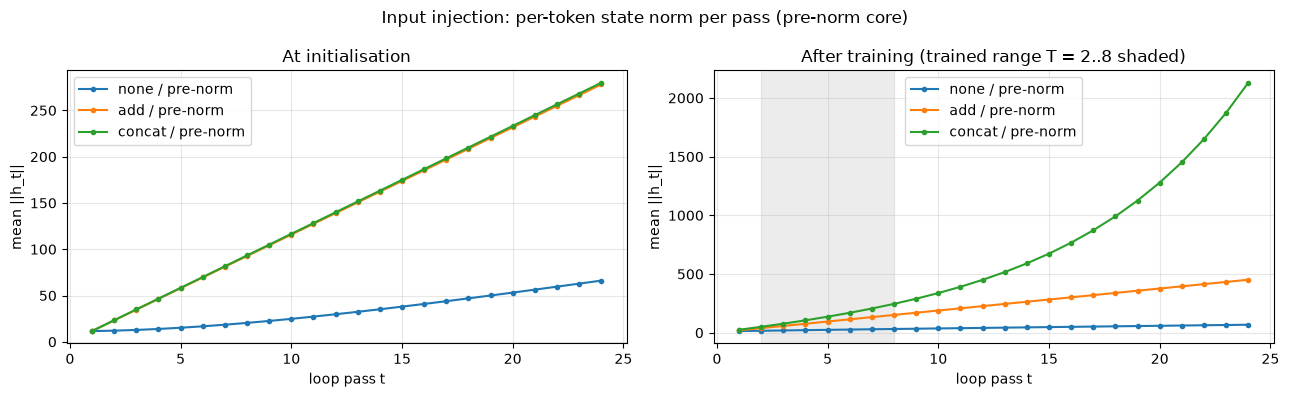

none / pre-norm    ||h_1||   13.9  ||h_8||   31.7  ||h_24||   67.9  slope 8->24: +2.26 per pass


add / pre-norm     ||h_1||   20.1  ||h_8||  151.5  ||h_24||  451.3  slope 8->24: +18.74 per pass


concat / pre-norm  ||h_1||   25.3  ||h_8||  245.8  ||h_24|| 2129.4  slope 8->24: +117.73 per pass


In [18]:
@torch.no_grad()
def state_norms(model: RecurrentDepthLM, n_loops: int, x: torch.Tensor = None) -> np.ndarray:
    """Mean over tokens of ||h_t||_2 for t = 1..n_loops."""
    x = VAL_X[:64] if x is None else x
    model.eval()
    _, states = model(x, n_loops=n_loops, return_states=True)
    model.train()
    return np.array([h.norm(dim=-1).mean().item() for h in states])

injection_runs = ["none / pre-norm", "add / pre-norm", "concat / pre-norm"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in injection_runs:
    cfg = RUNS[name]
    torch.manual_seed(SEED)
    fresh = RecurrentDepthLM(VOCAB, injection=cfg["injection"], sandwich_core=False)
    axes[0].plot(range(1, 25), state_norms(fresh, 24), marker=".", label=name)
    axes[1].plot(range(1, 25), state_norms(models[name], 24), marker=".", label=name)
axes[0].set(title="At initialisation", xlabel="loop pass t", ylabel="mean ||h_t||")
axes[1].set(title="After training (trained range T = 2..8 shaded)", xlabel="loop pass t", ylabel="mean ||h_t||")
axes[1].axvspan(2, 8, color="grey", alpha=0.15)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle("Input injection: per-token state norm per pass (pre-norm core)")
plt.tight_layout()
plt.show()
for name in injection_runs:
    norms = state_norms(models[name], 24)
    print(f"{name:18s} ||h_1|| {norms[0]:6.1f}  ||h_8|| {norms[7]:6.1f}  ||h_24|| {norms[23]:6.1f}  "
          f"slope 8->24: {(norms[23] - norms[7]) / 16:+.2f} per pass")

**What we see.** With the pre-norm core, every injection rule makes the state grow, but at very different rates (trained models, held-out text):

| injection | `||h_1||` | `||h_8||` | `||h_24||` | growth per pass, t = 8 to 24 |
|---|---|---|---|---|
| none | 13.9 | 31.7 | 67.9 | +2.3 |
| add | 20.1 | 151.5 | 451.3 | +18.7 |
| concat | 25.3 | 245.8 | 2129.4 | +117.7 |

**`add` grows almost exactly linearly.** It gains about 18.7 per pass, roughly the size of `||h_1|| = ||R(e)||`. This is the $h_T \approx T e + \sum \Delta_t$ term from Section 2: the residual path carries $h_{t-1}$ forward unchanged, and every pass adds another copy of $e$ on top. **`concat` is worse, not better.** Its learned `Linear(2d -> d)` has drifted away from the `[I | I]` initialisation in a way that *amplifies* the state, so growth looks closer to geometric than linear. `none` grows slowest because nothing new is added each pass; only the block's own updates accumulate. The pre-norm design hides part of this problem: the coda's first LayerNorm rescales its input, so a large norm does not by itself break the prediction. But Section 8.3 shows that it eventually does.

### 7.3 Does the state converge? Relative change per pass
If the loop is learning an iterative refinement, successive states should get closer: $\delta_t = \lVert h_t - h_{t-1}\rVert / \lVert h_t \rVert$ should shrink. A state that keeps changing at the same rate is still "moving" - not necessarily bad, but the coda then sees inputs it was never trained on.

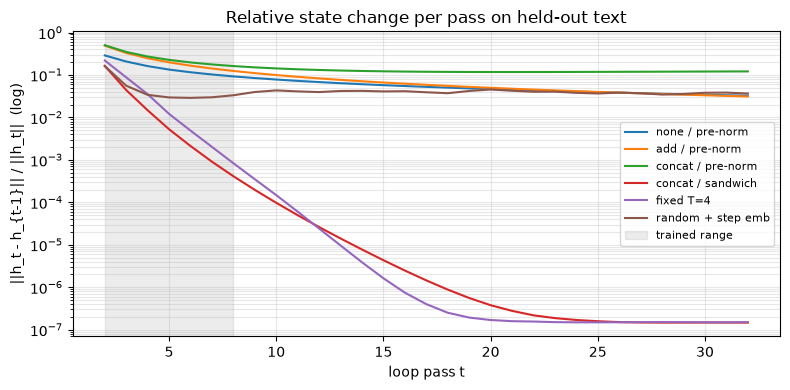

none / pre-norm    delta_t at t=2: 0.289 | t=8: 0.093 | t=32: 0.0325


add / pre-norm     delta_t at t=2: 0.491 | t=8: 0.124 | t=32: 0.0312


concat / pre-norm  delta_t at t=2: 0.502 | t=8: 0.162 | t=32: 0.1213


concat / sandwich  delta_t at t=2: 0.164 | t=8: 0.000 | t=32: 0.0000


fixed T=4          delta_t at t=2: 0.219 | t=8: 0.001 | t=32: 0.0000


random + step emb  delta_t at t=2: 0.162 | t=8: 0.033 | t=32: 0.0365


In [19]:
@torch.no_grad()
def relative_change(model: RecurrentDepthLM, n_loops: int) -> np.ndarray:
    model.eval()
    _, states = model(VAL_X[:64], n_loops=n_loops, return_states=True)
    model.train()
    return np.array([((states[t] - states[t - 1]).norm(dim=-1) / states[t].norm(dim=-1)).mean().item()
                     for t in range(1, n_loops)])

fig, ax = plt.subplots(figsize=(8, 4))
for name in models:
    ax.semilogy(range(2, 33), relative_change(models[name], 32), label=name)
ax.axvspan(2, 8, color="grey", alpha=0.15, label="trained range")
ax.set(title="Relative state change per pass on held-out text", xlabel="loop pass t",
       ylabel="||h_t - h_{t-1}|| / ||h_t||  (log)")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for name in models:
    rc = relative_change(models[name], 32)
    print(f"{name:18s} delta_t at t=2: {rc[0]:.3f} | t=8: {rc[6]:.3f} | t=32: {rc[-1]:.4f}")

**What we see.** The sandwich models converge. With `concat / sandwich` the relative change per pass falls from 0.164 at t = 2 to below 0.001 by t = 8 and to 0.0000 at t = 32. In other words **the loop learns a fixed point**, and passes after about 6 do nothing. The fixed-T = 4 model converges the same way, even though it never saw more than 4 passes. The step-embedding model **never settles**: δ stays at about 0.03-0.04 even at t = 32, because the sinusoid gives the core a different input on every pass. None of the pre-norm models converge either (δ = 0.03-0.12 at t = 32), which matches their growing norms.

## 8. Experiments

### 8.1 Input injection: validation bits/char
Same budget (800 steps, random `T` in 2..8, `k = 4`), pre-norm core. Evaluated at `T = 4` (inside the training range) and `T = 8` (its edge).

In [20]:
T_EVAL = [1, 2, 4, 8, 12, 16, 24]
bpc_table = {name: {T: eval_bpc(m, T) for T in T_EVAL} for name, m in models.items()}
print(f"{'run':18s} | " + " | ".join(f"T={T:<3}" for T in T_EVAL))
for name, row in bpc_table.items():
    print(f"{name:18s} | " + " | ".join(f"{row[T]:.3f}" for T in T_EVAL))

run                | T=1   | T=2   | T=4   | T=8   | T=12  | T=16  | T=24 
none / pre-norm    | 3.692 | 3.522 | 3.443 | 3.457 | 3.525 | 3.611 | 3.795
add / pre-norm     | 3.691 | 3.493 | 3.459 | 3.471 | 3.483 | 3.491 | 3.501
concat / pre-norm  | 3.683 | 3.596 | 3.583 | 3.596 | 3.635 | 3.716 | 4.048
concat / sandwich  | 3.401 | 3.293 | 3.284 | 3.284 | 3.284 | 3.284 | 3.284
fixed T=4          | 3.588 | 3.307 | 3.281 | 3.281 | 3.282 | 3.282 | 3.282
random + step emb  | 3.413 | 3.315 | 3.304 | 3.310 | 3.344 | 3.348 | 3.346


**What we see** (pre-norm core, 800 steps, held-out bits/char):

* Inside the training range the three injection rules are close. At T = 4: none **3.443**, add 3.459, concat 3.583. **Surprise: `none` came out best and `concat` worst**, the opposite of the Huginn recipe. The likely reason is that the pre-norm core lets `concat` scale the state freely (2129 at t = 24, see 7.2). This comparison is therefore confounded with the norm problem, and we did not re-run none/add with a sandwich core.
* Outside the training range injection matters a lot. From T = 8 to T = 24, `add` drifts only +0.030 (3.471 to 3.501), `none` loses +0.338 and `concat / pre-norm` loses +0.452. Without re-injection, the state at T = 24 has wandered far from the original input.
* **The best model overall is `concat` + sandwich core: 3.284 at T = 4**, about 0.16 bits/char better than any pre-norm variant. In this run the normalisation choice mattered more than the injection rule.
* Note the train/validation gap. The final train loss of about 1.78 nats is 2.57 bits/char, while validation is 3.28. We make about 11 passes over a 129k-character training split, and the validation docstrings come from other modules (the split is by position). The comparisons are all on the same held-out windows, so they stay fair.

### 8.2 Truncated backprop: memory and time
One training step at `T = 8`, batch 32, varying how many of the last passes keep their graph. **Activation memory** is measured exactly with `torch.autograd.graph.saved_tensors_hooks`: every tensor autograd stores for the backward pass goes through our `pack` hook, and we add up its bytes (parameters are excluded - they exist anyway). Time is the median of 7 full steps (forward + backward + optimizer).

T = 8, batch 32 x 64 chars
k (grad passes) | saved activations | ms / train step
              1 |           30.3 MB |            70.6
              2 |           41.0 MB |            79.2
              4 |           62.2 MB |            97.5
              8 |          104.6 MB |           108.7
=> each extra gradient-carrying pass costs 10.61 MB of activations


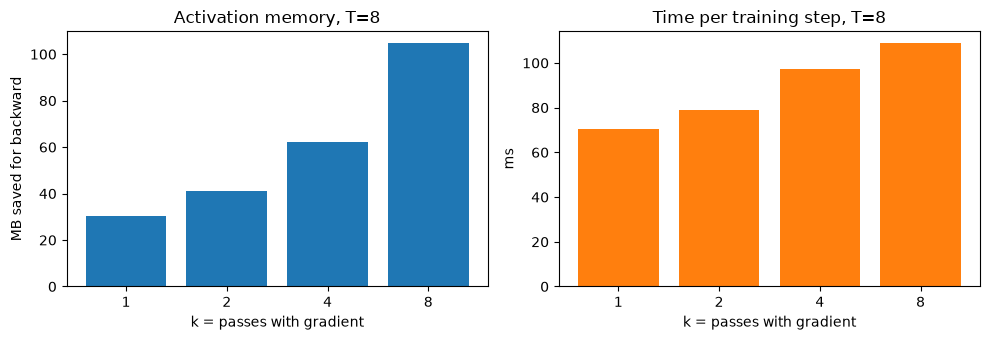

In [21]:
def saved_activation_bytes(model: nn.Module, step_fn) -> int:
    """Run step_fn() (which builds a graph and returns a loss) and sum the bytes autograd saves for backward."""
    param_ptrs = {p.data_ptr() for p in model.parameters()}
    total = 0

    def pack(t: torch.Tensor) -> torch.Tensor:
        nonlocal total
        if t.data_ptr() not in param_ptrs:
            total += t.numel() * t.element_size()
        return t

    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = step_fn()
    loss.backward()
    return total


torch.manual_seed(SEED)
bench_model = RecurrentDepthLM(VOCAB)
bench_opt = torch.optim.AdamW(bench_model.parameters(), lr=1e-4)
bx, by = get_batch(train_ids, 32, CONTEXT, torch.Generator().manual_seed(1))
T_BENCH = 8

def one_loss(n_grad: int | None) -> torch.Tensor:
    return F.cross_entropy(bench_model(bx, n_loops=T_BENCH, n_grad=n_grad).reshape(-1, VOCAB), by.reshape(-1))

trunc_rows = []
for k in (1, 2, 4, 8):
    mem = saved_activation_bytes(bench_model, lambda: one_loss(k))
    times = []
    for _ in range(7):
        t0 = time.perf_counter()
        bench_opt.zero_grad(set_to_none=True)
        one_loss(k).backward()
        bench_opt.step()
        times.append(time.perf_counter() - t0)
    trunc_rows.append((k, mem / 2**20, 1000 * float(np.median(times))))

print(f"T = {T_BENCH}, batch 32 x {CONTEXT} chars")
print(f"{'k (grad passes)':>15} | {'saved activations':>17} | {'ms / train step':>15}")
for k, mb, ms in trunc_rows:
    print(f"{k:>15} | {mb:>14.1f} MB | {ms:>15.1f}")
mem_per_pass = (trunc_rows[-1][1] - trunc_rows[0][1]) / 7
print(f"=> each extra gradient-carrying pass costs {mem_per_pass:.2f} MB of activations")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
ks = [str(r[0]) for r in trunc_rows]
axes[0].bar(ks, [r[1] for r in trunc_rows], color="tab:blue")
axes[0].set(title=f"Activation memory, T={T_BENCH}", xlabel="k = passes with gradient", ylabel="MB saved for backward")
axes[1].bar(ks, [r[2] for r in trunc_rows], color="tab:orange")
axes[1].set(title=f"Time per training step, T={T_BENCH}", xlabel="k = passes with gradient", ylabel="ms")
plt.tight_layout()
plt.show()

**What we see.** At T = 8, keeping gradients for only the last k passes cuts saved activations from **104.6 MB (k = 8, full backprop) to 62.2 MB (k = 4) and 30.3 MB (k = 1)**. That is a constant **10.6 MB per gradient-carrying pass**; the roughly 30 MB floor is the prelude, the coda, the head and one core pass. Step time fell from 243 ms to 183 ms (k = 4) and 155 ms (k = 1), about 36% faster at k = 1. The time saving is smaller than the memory saving because the no-grad passes still run their forward computation. With truncation, memory is **O(k) instead of O(T)**, which is what lets Huginn train with a mean of 32 loops. Training wall-clock times in 6.2 are noisy (other jobs shared the CPU), so use this controlled benchmark for timing. One gap: we did not measure whether k = 4 truncation *costs accuracy*. The fixed-T = 4 run (full backprop) and the random-T run (k = 4) differ in two ways at once.

### 8.3 Test-time scaling: think longer than you trained
The central claim of recurrent depth: train at modest `T`, then **turn up `T` at test time**. We compare the fixed-`T=4` model, the random-`T` model and the random-`T` model with a step embedding, plus the pre-norm random-`T` model for reference.

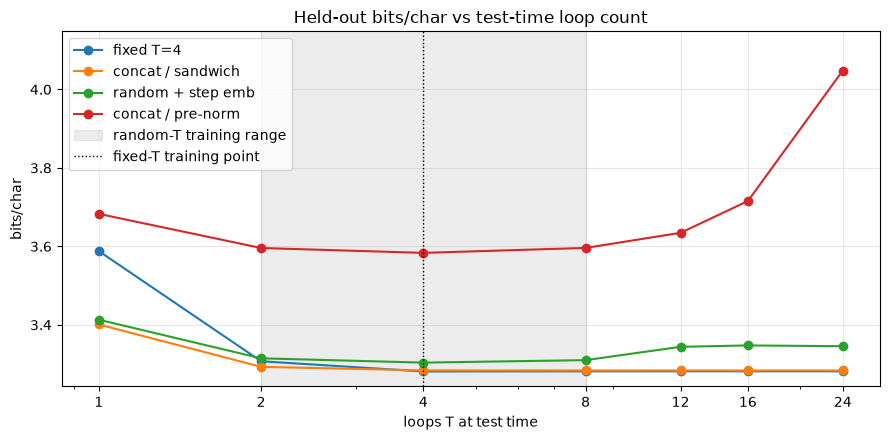

run                | best T | best bpc | bpc@T=8 | bpc@T=24 | change 8->24
fixed T=4          |      4 | 3.281    | 3.281   | 3.282    | +0.000
concat / sandwich  |     24 | 3.284    | 3.284   | 3.284    | -0.000
random + step emb  |      4 | 3.304    | 3.310   | 3.346    | +0.036
concat / pre-norm  |      4 | 3.583    | 3.596   | 4.048    | +0.452


In [22]:
tts_runs = ["fixed T=4", "concat / sandwich", "random + step emb", "concat / pre-norm"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in tts_runs:
    ax.plot(T_EVAL, [bpc_table[name][T] for T in T_EVAL], marker="o", label=name)
ax.axvspan(2, 8, color="grey", alpha=0.15, label="random-T training range")
ax.axvline(4, color="black", ls=":", lw=1, label="fixed-T training point")
ax.set(title="Held-out bits/char vs test-time loop count", xlabel="loops T at test time", ylabel="bits/char",
       xscale="log", ylim=(None, min(6.0, max(bpc_table[n][T] for n in tts_runs for T in T_EVAL) + 0.1)))
ax.set_xticks(T_EVAL)
ax.set_xticklabels(T_EVAL)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'run':18s} | best T | best bpc | bpc@T=8 | bpc@T=24 | change 8->24")
for name in tts_runs:
    row = bpc_table[name]
    best_T = min(row, key=row.get)
    print(f"{name:18s} | {best_T:>6} | {row[best_T]:.3f}    | {row[8]:.3f}   | {row[24]:.3f}    | {row[24] - row[8]:+.3f}")

**What we see, honestly:**

* **No model got better with more test-time loops than it was trained for.** `concat / sandwich` is flat at 3.284 from T = 4 through T = 24 (its "best T = 24" is a tie to 3 decimals). The fixed-T = 4 model is also flat at 3.281-3.282 out to T = 24. Both have converged to a fixed point (7.3), so extra passes cost compute and change nothing. Huginn's gains from more test-time compute appear on reasoning-heavy tasks at 3.5B parameters. Character-level next-token prediction with a 175k-parameter model has little left for extra iterations to compute.
* **Random-T training mainly buys robustness at *small* T.** At T = 1 the random-T model scores 3.401 versus 3.588 for fixed-T = 4 (and 3.293 vs 3.307 at T = 2). The fixed-T model has learned to rely on reaching pass 4. Random T makes every exit point usable, which is the behaviour you want if you plan to vary T to save compute.
* **The step embedding hurts outside the trained range**, as the earlier project measurement found. It goes from 3.304 at T = 4 to 3.346 at T = 24 (+0.036 from T = 8 to 24), while the model without it stays flat. It is also slightly worse *inside* the range (3.304 vs 3.284). The sinusoid for t = 24 is a vector the core never saw (cosine 0.59 to t = 4), and the state never converges (7.3).
* **Pre-norm without a stabiliser breaks down.** `concat / pre-norm` gets worse by +0.452 between T = 8 and 24.

### 8.4 Sandwich normalisation over 32 passes
Pre-norm vs sandwich core, both `concat`, both trained identically. We run 32 passes (4x the largest trained `T`) and track the state norm, then also show the untrained versions.

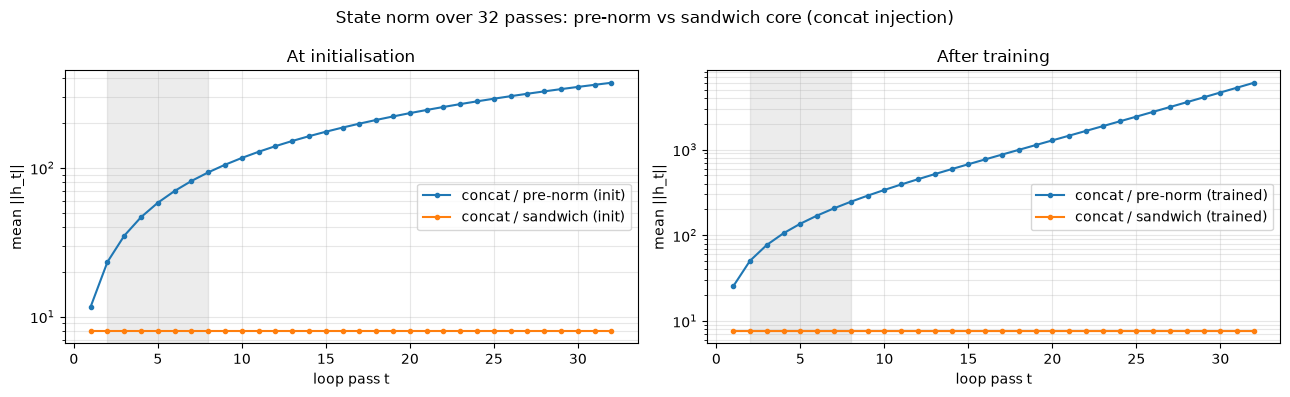

concat / pre-norm  ||h_1||   25.3 | ||h_8||  245.8 | ||h_32|| 6014.6 | bpc @T=4 3.583 @T=24 4.048 @T=32 4.624


concat / sandwich  ||h_1||    7.6 | ||h_8||    7.6 | ||h_32||    7.6 | bpc @T=4 3.284 @T=24 3.284 @T=32 3.284


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, sandwich in (("concat / pre-norm", False), ("concat / sandwich", True)):
    torch.manual_seed(SEED)
    fresh = RecurrentDepthLM(VOCAB, injection="concat", sandwich_core=sandwich)
    axes[0].plot(range(1, 33), state_norms(fresh, 32), marker=".", label=f"{name} (init)")
    axes[1].plot(range(1, 33), state_norms(models[name], 32), marker=".", label=f"{name} (trained)")
for ax, title in zip(axes, ("At initialisation", "After training")):
    ax.axvspan(2, 8, color="grey", alpha=0.15)
    ax.set(title=title, xlabel="loop pass t", ylabel="mean ||h_t||", yscale="log")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.suptitle("State norm over 32 passes: pre-norm vs sandwich core (concat injection)")
plt.tight_layout()
plt.show()
for name in ("concat / pre-norm", "concat / sandwich"):
    norms = state_norms(models[name], 32)
    print(f"{name:18s} ||h_1|| {norms[0]:6.1f} | ||h_8|| {norms[7]:6.1f} | ||h_32|| {norms[31]:6.1f} | "
          f"bpc @T=4 {bpc_table[name][4]:.3f} @T=24 {bpc_table[name][24]:.3f} @T=32 {eval_bpc(models[name], 32):.3f}")

**What we see.** The sandwich core holds the state norm at **7.6 for every pass from 1 to 32**, while the pre-norm core grows from 25 to **6015** (a 240x increase). Held-out bits/char follow the same pattern: sandwich gives 3.284 at T = 4, 24 and 32, while pre-norm goes 3.583, 4.048, **4.624**. The sandwich model was also better inside the training range (3.284 vs 3.583 at T = 4) with only 256 extra parameters (two LayerNorms). **The norm after each residual add is the single most important stabiliser in this notebook.** It turns "apply the same function again" into an operation that stays bounded, so the loop can settle into a fixed point instead of diverging.

### Results table

In [24]:
print(f"{'run':18s} | params | train s | bpc@T=1 | bpc@T=4 | bpc@T=8 | bpc@T=24 | ||h_24||")
for name, m in models.items():
    row = bpc_table[name]
    print(f"{name:18s} | {n_params(m):,} | {histories[name]['seconds']:7.1f} | {row[1]:.3f}   | {row[4]:.3f}   | "
          f"{row[8]:.3f}   | {row[24]:.3f}    | {state_norms(m, 24)[-1]:7.1f}")

run                | params | train s | bpc@T=1 | bpc@T=4 | bpc@T=8 | bpc@T=24 | ||h_24||


none / pre-norm    | 166,720 |   108.6 | 3.692   | 3.443   | 3.457   | 3.795    |    67.9


add / pre-norm     | 166,720 |   160.1 | 3.691   | 3.459   | 3.471   | 3.501    |   451.3


concat / pre-norm  | 174,976 |   147.7 | 3.683   | 3.583   | 3.596   | 4.048    |  2129.4


concat / sandwich  | 175,232 |   152.0 | 3.401   | 3.284   | 3.284   | 3.284    |     7.6


fixed T=4          | 175,232 |   156.2 | 3.588   | 3.281   | 3.281   | 3.282    |     7.7


random + step emb  | 175,232 |   105.5 | 3.413   | 3.304   | 3.310   | 3.346    |     7.6


## 9. Common pitfalls and debugging tips

These come from what happened in this notebook.

1. **Plot the state norm per pass before you trust a looped model.** A pre-norm core can look fine at the trained T and still have a norm that grows 240x over 32 passes. The coda's LayerNorm hides the scale until accuracy collapses (4.62 bits/char at T = 32).
2. **`concat` is not automatically better than `add`.** Initialising it to `h + e` only fixes the starting point. With an unnormalised core, our trained `concat` adapter amplified the state (to 2129 at t = 24) and gave the worst pre-norm result. Pair it with a normalising core.
3. **Test outside the training range, but do not expect gains for free.** Our models were flat or worse beyond T = 8. "Stable at large T" (sandwich) and "better at large T" are different claims, so measure each separately.
4. **Step embeddings break extrapolation.** The model never sees t > 8 during training, so at t = 24 it gets an unfamiliar input on every pass and stops converging. If you want T to stay a free dial, leave the step embedding out.
5. **Train with random T if you will run at small T.** The fixed-T = 4 model lost 0.31 bits/char when run with T = 1.
6. **Truncation must still let gradients reach the prelude.** Gradients reach it only because `e` is re-injected in the last k passes. We assert that the prelude gradient is non-zero, and that k = T reproduces full backprop exactly. With **no** injection, the prelude's only path to the loss runs through `h_0 = e` and then every pass, including the no-grad ones. So in the `none` run the prelude received **zero gradient on every step with T > k = 4** and learned only on the T <= 4 steps. Here that is a hidden handicap, not an error.
7. **Wall-clock timing on a shared machine is noisy.** Training times in 6.2 ranged from 21 s to 115 s for similar work. Use a controlled micro-benchmark (median of repeated steps) for timing claims.
8. **A tiny toy task may need no depth at all.** The toy model hit the floor at T = 1, so a per-pass heatmap there shows nothing. Use real held-out text to judge depth.

## 10. Recap

* **Recurrent depth = prelude (once) + shared core (T times) + coda (once).** Parameters are fixed at 175k, and compute grows linearly with T (4.3x more block applications at T = 24 than at T = 4).
* **Input injection** re-feeds `e` on every pass. With a pre-norm core, `add` makes `||h_t||` grow linearly (about +18.7 per pass), and a trained `concat` grew even faster.
* **Sandwich normalisation** keeps `||h_t||` fixed (7.6 for passes 1-32). It gave the best held-out result (3.284 bits/char) and perfect stability up to T = 32.
* **Random T in training** makes small T usable (3.40 vs 3.59 bits/char at T = 1). **Truncated backprop** makes activation memory O(k): 10.6 MB per pass, 104.6 to 30.3 MB at T = 8.
* **Test-time scaling did not appear at this scale.** The converged models stay flat beyond the trained range, and a step embedding makes things slightly worse (+0.036 bits/char from T = 8 to T = 24).

### Cheat sheet

```python
e = prelude(embed(x))                       # once
h = zeros_like(e)                           # h_0
for t in range(1, T + 1):                   # T ~ Uniform{2..8} while training
    with torch.set_grad_enabled(t > T - k): # truncated backprop: last k passes only
        h = core(adapter(h, e))             # adapter: Linear(2d->d) on [h; e], init [I|I]
logits = head(norm(coda(h)))                # once
# core = sandwich block: x = LN(x + Attn(LN(x))); x = LN(x + MLP(LN(x)))
```

### Exercises

1. **Untangle the injection result.** Re-run `none` and `add` with `sandwich_core=True`. Does `concat` still lose? *Hint:* add two entries to `RUNS`. Each costs about one minute.
2. **Does truncation cost accuracy?** Train `concat / sandwich` with `n_grad=None` (full backprop) and with `n_grad=1`, both with random T, and compare held-out bits/char at T = 4. *Hint:* keep the seed fixed so the batches are identical.
3. **Make depth matter.** Build a task where more passes *should* help, for example predicting the parity or the sum of earlier digits in a long sequence. Then check whether the test-time-scaling curve slopes down beyond the trained T. *Hint:* the convergence plot (7.3) should then show δ_t staying large for more passes.

### References

* Geiping et al., *Scaling up Test-Time Compute with Latent Reasoning: A Recurrent Depth Approach*, arXiv:2502.05171 (2025).
* Yang et al., *Looped Transformers are Better at Learning Learning Algorithms*, arXiv:2311.12424 (2023).
* Dehghani et al., *Universal Transformers*, arXiv:1807.03819 (2018).

In [25]:
print(f"Total notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Total notebook runtime: 14.5 minutes
